<a href="https://colab.research.google.com/github/seo104/26-2-ESAA/blob/main/%EC%97%91%EC%8A%A4%ED%8A%B8%EB%9D%BC_%ED%8A%B8%EB%A6%AC(%EC%88%98%EC%A0%95%EB%B3%B8).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

##와인 품질 분류 모델링 - Extra Trees

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import ExtraTreesClassifier
from sklearn.model_selection import (
    StratifiedKFold,
    StratifiedGroupKFold,
    cross_val_score
)
from sklearn.base import clone

# 데이터 불러오기
train = pd.read_csv('/content/train(와인).csv')
test = pd.read_csv('/content/test(와인).csv')

print('Train 데이터 크기:', train.shape)
print('Test 데이터 크기:', test.shape)

Train 데이터 크기: (5497, 14)
Test 데이터 크기: (1000, 13)


###1. 공통 전처리
회의에서 확정한 전처리 기준은
- 레드와 화이트 데이터를 통합하여 사용
- type은 화이트=1, 레드=0인 is_white로 변환
- bound_so2(total sulfur dioxide - free sulfur dioxide)를 추가
- density를 포함한 기존 화학 성분 변수는 모두 유지
- 이상치 삭제, 로그 변환, 중복 제거 및 불균형 처리는 적용하지 않음
- index와 quality는 입력 변수에서 제외

In [2]:
#공통 전처리 함수
def make_x(df):
    X = df.drop(columns=['index', 'quality'], errors='ignore').copy()

    X['is_white'] = X['type'].map({'red': 0, 'white': 1})
    X = X.drop(columns=['type'])

    X['bound_so2'] = (
        X['total sulfur dioxide'] - X['free sulfur dioxide']
    )
    return X


def make_xy(df):
    X = make_x(df)
    y = df['quality'].copy()
    return X, y


X, y = make_xy(train)
X_test = make_x(test)

print('X shape:', X.shape)
print('X_test shape:', X_test.shape)

X shape: (5497, 13)
X_test shape: (1000, 13)


###2. 기본 모델 및 검증 규칙
모든 모델은 동일한 검증 조건으로 비교
- 검증 방법: StratifiedKFold
- Fold 수: 5
- shuffle=True, random_state=42
- 평가 지표: Accuracy
- 결과 기록: Fold별 점수, 평균, 표준편차
- 기준선 Accuracy: 0.4395

먼저 회의에서 사용한 기본 Extra Trees 모델의 성능을 확인한다.

In [3]:
# 확정된 일반 교차검증
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)


def evaluate(model, X, y):
    cv_model = clone(model)

    if 'n_jobs' in cv_model.get_params(deep=False):
        cv_model.set_params(n_jobs=1)

    scores = cross_val_score(
        cv_model,
        X,
        y,
        cv=cv,
        scoring='accuracy',
        n_jobs=2
    )

    print('Fold별 Accuracy:', np.round(scores, 4))
    print(f'평균 Accuracy: {scores.mean():.4f}')
    print(f'표준편차: {scores.std():.4f}')

    return scores


# 기본 Extra Trees 모델
base_model = ExtraTreesClassifier(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

base_scores = evaluate(base_model, X, y)

Fold별 Accuracy: [0.6964 0.6836 0.6779 0.6797 0.6615]
평균 Accuracy: 0.6798
표준편차: 0.0112


###3. 하이퍼파라미터 튜닝
Extra Trees의 주요 하이퍼파라미터를 변경하여 성능을 비교한다.
- n_estimators: 트리 개수
- max_depth: 트리의 최대 깊이
- min_samples_split: 노드를 분할하기 위한 최소 샘플 수
- min_samples_leaf: 리프 노드에 필요한 최소 샘플 수
- max_features: 분할 시 고려할 변수 수

트리 깊이와 리프 샘플 수를 조절하여 과적합을 줄일 수 있는지 확인한다.

In [4]:
from sklearn.model_selection import RandomizedSearchCV

# 실험할 파라미터 범위
# 기존 탐색에서 성능이 높았던 기본값(sqrt)과 그 주변의 작은 값을 포함
param_dist = {
    'n_estimators': [200, 300, 400],
    'max_depth': [None, 20, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 3, 4],
    'max_features': ['sqrt', 0.2, 0.3, 0.4]
}

# 기본 모델
et = ExtraTreesClassifier(
    random_state=42,
    n_jobs=1
)

# 무작위 하이퍼파라미터 탐색
search = RandomizedSearchCV(
    estimator=et,
    param_distributions=param_dist,
    n_iter=10,
    scoring='accuracy',
    cv=cv,
    random_state=42,
    n_jobs=2,
    verbose=2
)

search.fit(X, y)

# 실험 결과 정리
results = []

for i, params in enumerate(search.cv_results_['params']):
    row = {
        '실험': i + 1,
        **params,
        'CV 평균': search.cv_results_['mean_test_score'][i],
        'CV 표준편차': search.cv_results_['std_test_score'][i]
    }

    for fold in range(5):
        row[f'Fold {fold+1}'] = (
            search.cv_results_[f'split{fold}_test_score'][i]
        )

    results.append(row)

result_df = pd.DataFrame(results).sort_values(
    'CV 평균', ascending=False
).reset_index(drop=True)

display(result_df.round(4))

print("최고 CV Accuracy:", search.best_score_)
print("최적 파라미터:", search.best_params_)


Fitting 5 folds for each of 10 candidates, totalling 50 fits


,실험,n_estimators,min_samples_split,min_samples_leaf,max_features,max_depth,CV 평균,CV 표준편차,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5
0,2,200,5,1,0.3,NaN,0.6764,0.0081,0.6836,0.6800,0.6779,0.6797,0.6606
1,10,300,5,1,sqrt,20.0,0.6747,0.0094,0.6891,0.6818,0.6688,0.6706,0.6633
2,3,200,2,1,0.2,20.0,0.6715,0.0067,0.6782,0.6773,0.6624,0.6752,0.6642
3,8,300,2,2,sqrt,20.0,0.6680,0.0108,0.6764,0.6845,0.6615,0.6624,0.6551
4,6,400,5,3,0.4,20.0,0.6591,0.0078,0.6673,0.6691,0.6570,0.6506,0.6515
5,7,200,2,3,0.4,30.0,0.6591,0.0097,0.6727,0.6682,0.6542,0.6533,0.6470
6,1,300,2,4,0.4,30.0,0.6402,0.0098,0.6518,0.6500,0.6260,0.6397,0.6333
7,5,400,5,4,0.3,30.0,0.6185,0.0067,0.6300,0.6200,0.6187,0.6133,0.6106
8,4,200,5,4,sqrt,NaN,0.6178,0.0070,0.6300,0.6173,0.6197,0.6124,0.6096
9,9,200,10,2,0.2,20.0,0.6065,0.0025,0.6091,0.6055,0.6096,0.6033,0.6051


최고 CV Accuracy: 0.6763669451567541
최적 파라미터: {'n_estimators': 200, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_features': 0.3, 'max_depth': None}


실험 결과를 비교하여 기본 모델보다 Accuracy가 높은 조합을 확인한다. 평균 점수뿐 아니라 표준편차와 Fold별 점수도 함께 확인한다.

###4. 그룹 교차검증
Train 데이터에는 동일한 성분 조합의 중복 행이 존재하고, Test 데이터에도 Train과 동일한 성분 조합이 확인되었다.

따라서 동일한 성분 조합이 학습 Fold와 검증 Fold에 나뉘지 않도록 `StratifiedGroupKFold`를 이용해 추가 평가한다.

그룹 CV는 중복된 성분 조합이 서로 다른 Fold에 포함되는 것을 방지했을 때 모델 성능이 어떻게 달라지는지 확인하기 위한 보조 진단이다.

최종 하이퍼파라미터는 일반 `StratifiedKFold` 기반 CV Accuracy를 기준으로 선정하며, 그룹 CV 결과는 중복 데이터의 영향을 확인하는 용도로 활용한다.

그룹은 index, quality를 제외한 원본 입력 변수의 조합을 기준으로 생성한다.

In [5]:
# 확정된 그룹 교차검증
cv_group = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

group_features = [
    col for col in train.columns
    if col not in ['index', 'quality']
]

groups = train.groupby(
    group_features,
    sort=False
).ngroup()


def evaluate_group(model, X, y, groups):
    cv_model = clone(model)

    if 'n_jobs' in cv_model.get_params(deep=False):
        cv_model.set_params(n_jobs=1)

    scores = cross_val_score(
        cv_model,
        X,
        y,
        cv=cv_group,
        groups=groups,
        scoring='accuracy',
        n_jobs=2
    )

    print('Group Fold별 Accuracy:', np.round(scores, 4))
    print(f'Group CV 평균: {scores.mean():.4f}')
    print(f'Group CV 표준편차: {scores.std():.4f}')

    return scores

###5. 최종 후보 비교
일반 교차검증에서 CV Accuracy가 높은 상위 3개 모델을 선정한 뒤, 동일한 모델을 그룹 교차검증으로 추가 평가한다.

일반 CV와 그룹 CV의 평균 Accuracy 및 표준편차를 비교하여 중복 성분 조합이 모델 평가에 미치는 영향을 확인한다.

최종 모델의 하이퍼파라미터는 그룹 CV 결과가 아닌 일반 CV를 기준으로 선정한다.

In [6]:
top_candidates = result_df.head(3)
final_results = []

for _, row in top_candidates.iterrows():
    params = {
        'n_estimators': int(row['n_estimators']),
        'max_depth': None if pd.isna(row['max_depth']) else int(row['max_depth']),
        'min_samples_split': int(row['min_samples_split']),
        'min_samples_leaf': int(row['min_samples_leaf']),
        'max_features': row['max_features']
    }

    model = ExtraTreesClassifier(
        **params,
        random_state=42,
        n_jobs=1
    )

    normal_scores = evaluate(model, X, y)
    group_scores = evaluate_group(model, X, y, groups)

    final_results.append({
        '파라미터': params,
        '일반 CV 평균': normal_scores.mean(),
        '일반 CV 표준편차': normal_scores.std(),
        '그룹 CV 평균': group_scores.mean(),
        '그룹 CV 표준편차': group_scores.std()
    })

final_result_df = pd.DataFrame(final_results)
display(final_result_df)

Fold별 Accuracy: [0.6836 0.68   0.6779 0.6797 0.6606]
평균 Accuracy: 0.6764
표준편차: 0.0081
Group Fold별 Accuracy: [0.5978 0.5887 0.5765 0.5588 0.5818]
Group CV 평균: 0.5807
Group CV 표준편차: 0.0131
Fold별 Accuracy: [0.6891 0.6818 0.6688 0.6706 0.6633]
평균 Accuracy: 0.6747
표준편차: 0.0094
Group Fold별 Accuracy: [0.6005 0.5942 0.5655 0.5642 0.5836]
Group CV 평균: 0.5816
Group CV 표준편차: 0.0147
Fold별 Accuracy: [0.6782 0.6773 0.6624 0.6752 0.6642]
평균 Accuracy: 0.6715
표준편차: 0.0067
Group Fold별 Accuracy: [0.5807 0.5851 0.5765 0.5722 0.5892]
Group CV 평균: 0.5807
Group CV 표준편차: 0.0060


,파라미터,일반 CV 평균,일반 CV 표준편차,그룹 CV 평균,그룹 CV 표준편차
0,"{'n_estimators': 200, 'max_depth': None, 'min_...",0.676367,0.008101,0.580739,0.013077
1,"{'n_estimators': 300, 'max_depth': 20, 'min_sa...",0.674728,0.009367,0.581614,0.014717
2,"{'n_estimators': 200, 'max_depth': 20, 'min_sa...",0.671455,0.006730,0.580746,0.006024


###6. 최종 모델 학습 및 변수 중요도

일반 StratifiedKFold 최종 검증
Fold별 Accuracy: [0.6836 0.68   0.6779 0.6797 0.6606]
평균 Accuracy: 0.6764
표준편차: 0.0081
중복 조합 영향 확인용 Group CV 진단
Group Fold별 Accuracy: [0.5978 0.5887 0.5765 0.5588 0.5818]
Group CV 평균: 0.5807
Group CV 표준편차: 0.0131


,변수,중요도
10,alcohol,0.142095
1,volatile acidity,0.096133
7,density,0.083883
9,sulphates,0.079465
12,bound_so2,0.077147
3,residual sugar,0.074922
5,free sulfur dioxide,0.074677
6,total sulfur dioxide,0.074460
2,citric acid,0.073094
8,pH,0.072577


/tmp/ipykernel_4011/3143026303.py:31: UserWarning: Glyph 51473 (\N{HANGUL SYLLABLE JUNG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_4011/3143026303.py:31: UserWarning: Glyph 50836 (\N{HANGUL SYLLABLE YO}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_4011/3143026303.py:31: UserWarning: Glyph 46020 (\N{HANGUL SYLLABLE DO}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_4011/3143026303.py:31: UserWarning: Glyph 48320 (\N{HANGUL SYLLABLE BYEON}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_4011/3143026303.py:31: UserWarning: Glyph 49688 (\N{HANGUL SYLLABLE SU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 48320 (\N{HANGUL SYLLABLE BYEON}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWar

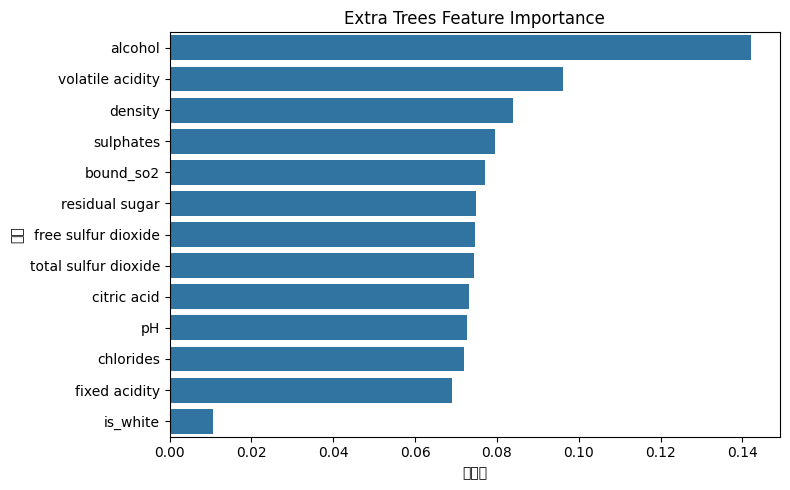

In [7]:
best_params = search.best_params_

best_model = ExtraTreesClassifier(
    **best_params,
    random_state=42,
    n_jobs=-1
)

print('일반 StratifiedKFold 최종 검증')
final_scores = evaluate(best_model, X, y)

print('중복 조합 영향 확인용 Group CV 진단')
final_group_scores = evaluate_group(
    best_model, X, y, groups
)

# 전체 Train 데이터로 최종 학습
best_model.fit(X, y)

# 변수 중요도 확인
importance = pd.DataFrame({
    '변수': X.columns,
    '중요도': best_model.feature_importances_
}).sort_values('중요도', ascending=False)

display(importance)

plt.figure(figsize=(8, 5))
sns.barplot(data=importance, x='중요도', y='변수')
plt.title('Extra Trees Feature Importance')
plt.tight_layout()
plt.show()

- alcohol이 가장 높은 중요도를 보여 와인 품질 예측에 주요하게 활용되는 변수임을 확인하였다.
- volatile acidity와 sulphates도 상대적으로 높은 중요도를 보였다.
- free sulfur dioxide, density, bound_so2 등 여러 화학 성분 변수가 고르게 활용되었다.
- is_white는 다른 변수에 비해 중요도가 낮게 나타났다.

단, 변수 중요도는 모델의 예측 과정에서 각 변수가 활용된 정도를 나타내며, 변수와 품질 사이의 인과관계나 영향의 방향을 의미하지는 않는다.

###7. Test 예측 및 결과 정리
최종 모델로 Test 데이터를 예측하고 제출 파일을 저장

제출 양식이 제공된 경우 기존 열 구조를 유지

In [8]:
# Test 예측
test_pred = best_model.predict(X_test)

# 제출 파일 생성
submission = pd.read_csv('/content/sample_submission.csv')
submission['quality'] = test_pred

submission.to_csv(
    '/content/submission_extra_trees.csv',
    index=False
)

display(submission.head())

,index,quality
0,0,5
1,1,6
2,2,6
3,3,5
4,4,6


데이콘 제출 결과 Accuracy 0.701